In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import resnet50

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [3]:
test_df = pd.read_csv("test/_classes.csv")

test_df["split"] = "test"

print("Test Images:", len(test_df))
print(test_df.head())

Test Images: 176
                                            filename  \
0  Copy-of-mild-ventriculomegaly-18c_aug_2_png_jp...   
1  Copy-of-intracranial-hemorrdge-34a_aug_4_png_j...   
2  Copy-of-moderate-ventriculomegaly-34_aug_4_png...   
3  Copy-of-polencephaly30k_aug_2_png_jpg.rf.05b0e...   
4  Copy-of-encephalocele-4-32c_aug_4_png_jpg.rf.0...   

    anold-chiari-malformation   arachnoid-cyst   cerebellah-hypoplasia  \
0                           0                0                       0   
1                           0                0                       0   
2                           0                0                       0   
3                           0                0                       0   
4                           0                0                       0   

    colphocephaly   encephalocele   holoprosencephaly   hydracenphaly  \
0               0               0                   0               0   
1               0               0                   0  

In [4]:
label_columns = test_df.columns[1:-1]

print("Number of classes:", len(label_columns))
print(label_columns.tolist())

Number of classes: 16
[' anold-chiari-malformation', ' arachnoid-cyst', ' cerebellah-hypoplasia', ' colphocephaly', ' encephalocele', ' holoprosencephaly', ' hydracenphaly', ' intracranial-hemorrdge', ' intracranial-tumor', ' m-magna', ' mild-ventriculomegaly', ' moderate-ventriculomegaly', ' normal', ' polencephaly', ' severe-ventriculomegaly', ' vein-of-galen']


In [5]:
test_df["label"] = test_df[label_columns].idxmax(axis=1)

print(test_df[["filename", "label"]].head())

                                            filename  \
0  Copy-of-mild-ventriculomegaly-18c_aug_2_png_jp...   
1  Copy-of-intracranial-hemorrdge-34a_aug_4_png_j...   
2  Copy-of-moderate-ventriculomegaly-34_aug_4_png...   
3  Copy-of-polencephaly30k_aug_2_png_jpg.rf.05b0e...   
4  Copy-of-encephalocele-4-32c_aug_4_png_jpg.rf.0...   

                        label  
0       mild-ventriculomegaly  
1      intracranial-hemorrdge  
2   moderate-ventriculomegaly  
3                polencephaly  
4               encephalocele  


In [6]:
with open("class_mapping.json", "r") as f:
    class_to_idx = json.load(f)

classes = list(class_to_idx.keys())

idx_to_class = {
    int(idx): cls
    for cls, idx in class_to_idx.items()
}

num_classes = len(classes)

print("Number of classes:", num_classes)
print(classes)

Number of classes: 16
[' anold-chiari-malformation', ' arachnoid-cyst', ' cerebellah-hypoplasia', ' colphocephaly', ' encephalocele', ' holoprosencephaly', ' hydracenphaly', ' intracranial-hemorrdge', ' intracranial-tumor', ' m-magna', ' mild-ventriculomegaly', ' moderate-ventriculomegaly', ' normal', ' polencephaly', ' severe-ventriculomegaly', ' vein-of-galen']


In [7]:
test_df["target"] = test_df["label"].map(class_to_idx)

print(test_df[["filename", "label", "target"]].head())

                                            filename  \
0  Copy-of-mild-ventriculomegaly-18c_aug_2_png_jp...   
1  Copy-of-intracranial-hemorrdge-34a_aug_4_png_j...   
2  Copy-of-moderate-ventriculomegaly-34_aug_4_png...   
3  Copy-of-polencephaly30k_aug_2_png_jpg.rf.05b0e...   
4  Copy-of-encephalocele-4-32c_aug_4_png_jpg.rf.0...   

                        label  target  
0       mild-ventriculomegaly      10  
1      intracranial-hemorrdge       7  
2   moderate-ventriculomegaly      11  
3                polencephaly      13  
4               encephalocele       4  


In [8]:
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [9]:
class FetalTestDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = os.path.join(
            row["split"],
            row["filename"]
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["target"])

        return image, label

In [10]:
test_dataset = FetalTestDataset(
    test_df,
    test_transform
)

print("Test Dataset:", len(test_dataset))

Test Dataset: 176


In [11]:
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("Test DataLoader Created")

Test DataLoader Created


In [12]:
model = resnet50(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

print("ResNet50 architecture created.")

ResNet50 architecture created.


In [13]:
model_path = "best_resnet50.pth"

model.load_state_dict(
    torch.load(
        model_path,
        map_location=device
    )
)

model.eval()

print("Best ResNet50 model loaded successfully.")

Best ResNet50 model loaded successfully.


In [14]:
all_labels = []
all_predictions = []
all_probabilities = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

all_labels = np.array(all_labels)

all_predictions = np.array(all_predictions)

all_probabilities = np.array(all_probabilities)

print("Predictions generated.")
print("Number of predictions:", len(all_predictions))

Predictions generated.
Number of predictions: 176


In [15]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 82.95%


In [16]:
precision_macro = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print(f"Macro Precision    : {precision_macro:.4f}")
print(f"Macro Recall       : {recall_macro:.4f}")
print(f"Macro F1-Score     : {f1_macro:.4f}")

print()

print(f"Weighted Precision : {precision_weighted:.4f}")
print(f"Weighted Recall    : {recall_weighted:.4f}")
print(f"Weighted F1-Score  : {f1_weighted:.4f}")

Macro Precision    : 0.8590
Macro Recall       : 0.8422
Macro F1-Score     : 0.8324

Weighted Precision : 0.8429
Weighted Recall    : 0.8295
Weighted F1-Score  : 0.8279


In [17]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=classes,
    zero_division=0
)

print(report)

                            precision    recall  f1-score   support

 anold-chiari-malformation       1.00      0.33      0.50         3
            arachnoid-cyst       0.93      1.00      0.96        13
     cerebellah-hypoplasia       0.74      0.88      0.80        16
             colphocephaly       0.91      0.91      0.91        11
             encephalocele       0.92      0.73      0.81        15
         holoprosencephaly       1.00      1.00      1.00         4
             hydracenphaly       1.00      1.00      1.00         2
    intracranial-hemorrdge       0.88      0.88      0.88         8
        intracranial-tumor       0.00      0.00      0.00         0
                   m-magna       0.80      1.00      0.89         4
     mild-ventriculomegaly       0.76      0.79      0.78        24
 moderate-ventriculomegaly       0.80      0.62      0.70        26
                    normal       0.96      0.96      0.96        24
              polencephaly       0.50      0.86

In [18]:
report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    "classification_report.csv"
)

display(report_df)

,precision,recall,f1-score,support
anold-chiari-malformation,1.000000,0.333333,0.500000,3.000000
arachnoid-cyst,0.928571,1.000000,0.962963,13.000000
cerebellah-hypoplasia,0.736842,0.875000,0.800000,16.000000
colphocephaly,0.909091,0.909091,0.909091,11.000000
encephalocele,0.916667,0.733333,0.814815,15.000000
holoprosencephaly,1.000000,1.000000,1.000000,4.000000
hydracenphaly,1.000000,1.000000,1.000000,2.000000
intracranial-hemorrdge,0.875000,0.875000,0.875000,8.000000
intracranial-tumor,0.000000,0.000000,0.000000,0.000000
m-magna,0.800000,1.000000,0.888889,4.000000


In [20]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

print(cm)

[[ 1  1  0  0  0  0  0  0  0  1  0  0  0  0  0  0]
 [ 0 13  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 14  1  0  0  0  0  0  0  0  1  0  0  0  0]
 [ 0  0  0 10  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 11  0  0  0  0  0  3  0  0  0  1  0]
 [ 0  0  0  0  0  4  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  7  0  0  0  0  0  1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  4  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 19  1  1  3  0  0]
 [ 0  0  4  0  0  0  0  1  0  0  2 16  0  1  2  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 23  1  0  0]
 [ 0  0  1  0  0  0  0  0  0  0  0  0  0  6  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  1  2  0  0 16  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]]


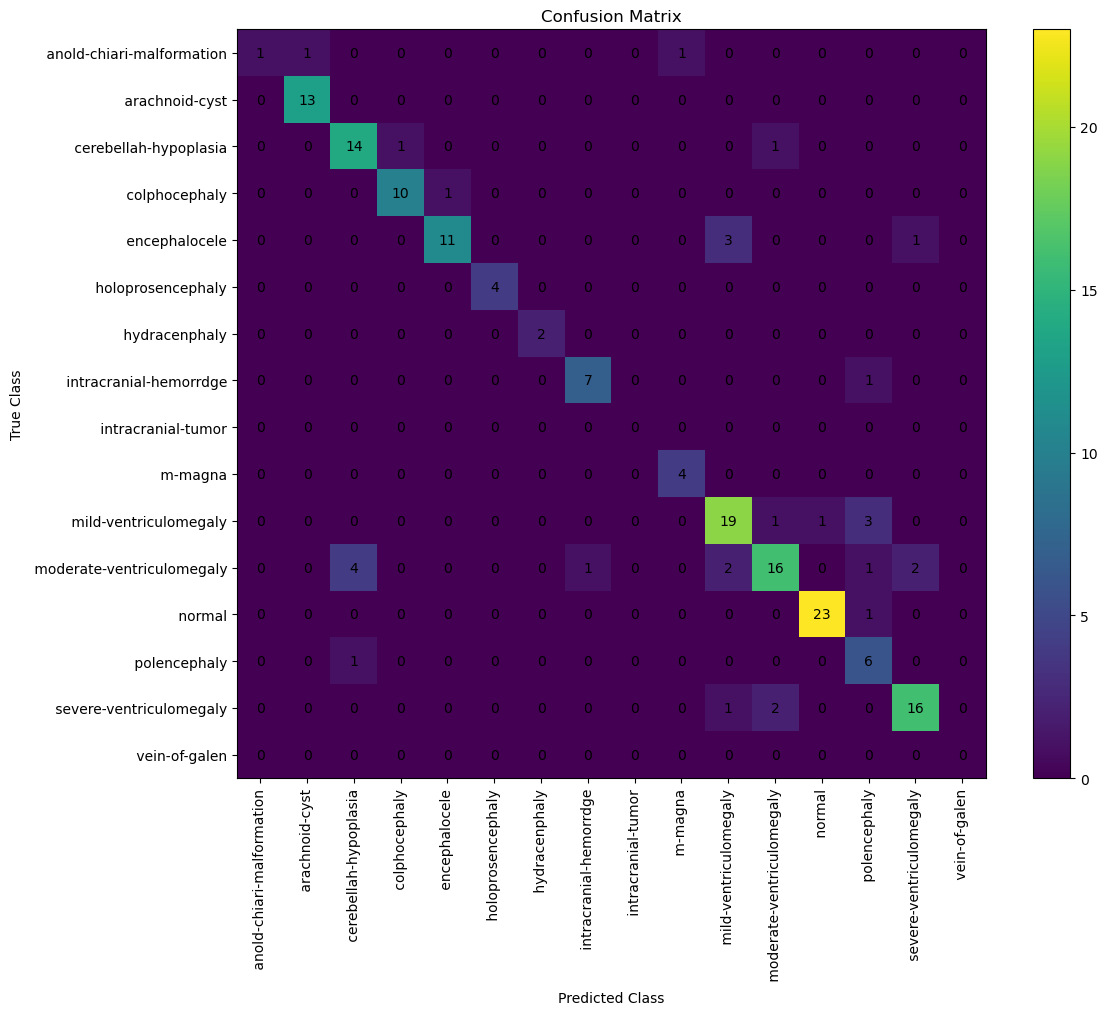

In [21]:
plt.figure(figsize=(12, 10))

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title("Confusion Matrix")

plt.colorbar()

plt.xticks(
    np.arange(num_classes),
    classes,
    rotation=90
)

plt.yticks(
    np.arange(num_classes),
    classes
)

plt.xlabel("Predicted Class")

plt.ylabel("True Class")

for i in range(num_classes):

    for j in range(num_classes):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
per_class_results = []

for i, cls in enumerate(classes):

    tp = cm[i, i]

    fn = cm[i, :].sum() - tp

    fp = cm[:, i].sum() - tp

    tn = cm.sum() - (tp + fn + fp)

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    per_class_results.append({
        "Class": cls,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    })

per_class_df = pd.DataFrame(
    per_class_results
)

display(per_class_df)

,Class,TP,TN,FP,FN,Sensitivity,Specificity
0,anold-chiari-malformation,1,173,0,2,0.333333,1.000000
1,arachnoid-cyst,13,162,1,0,1.000000,0.993865
2,cerebellah-hypoplasia,14,155,5,2,0.875000,0.968750
3,colphocephaly,10,164,1,1,0.909091,0.993939
4,encephalocele,11,160,1,4,0.733333,0.993789
5,holoprosencephaly,4,172,0,0,1.000000,1.000000
6,hydracenphaly,2,174,0,0,1.000000,1.000000
7,intracranial-hemorrdge,7,167,1,1,0.875000,0.994048
8,intracranial-tumor,0,176,0,0,0.000000,1.000000
9,m-magna,4,171,1,0,1.000000,0.994186


In [24]:
per_class_df.to_csv(
    "per_class_sensitivity_specificity.csv",
    index=False
)

print("Per-class results saved.")

Per-class results saved.


In [25]:
y_true_bin = label_binarize(
    all_labels,
    classes=list(range(num_classes))
)

roc_auc_macro = roc_auc_score(
    y_true_bin,
    all_probabilities,
    multi_class="ovr",
    average="macro"
)

roc_auc_weighted = roc_auc_score(
    y_true_bin,
    all_probabilities,
    multi_class="ovr",
    average="weighted"
)

print(f"Macro ROC-AUC    : {roc_auc_macro:.4f}")
print(f"Weighted ROC-AUC : {roc_auc_weighted:.4f}")

Macro ROC-AUC    : nan
Weighted ROC-AUC : 0.9732


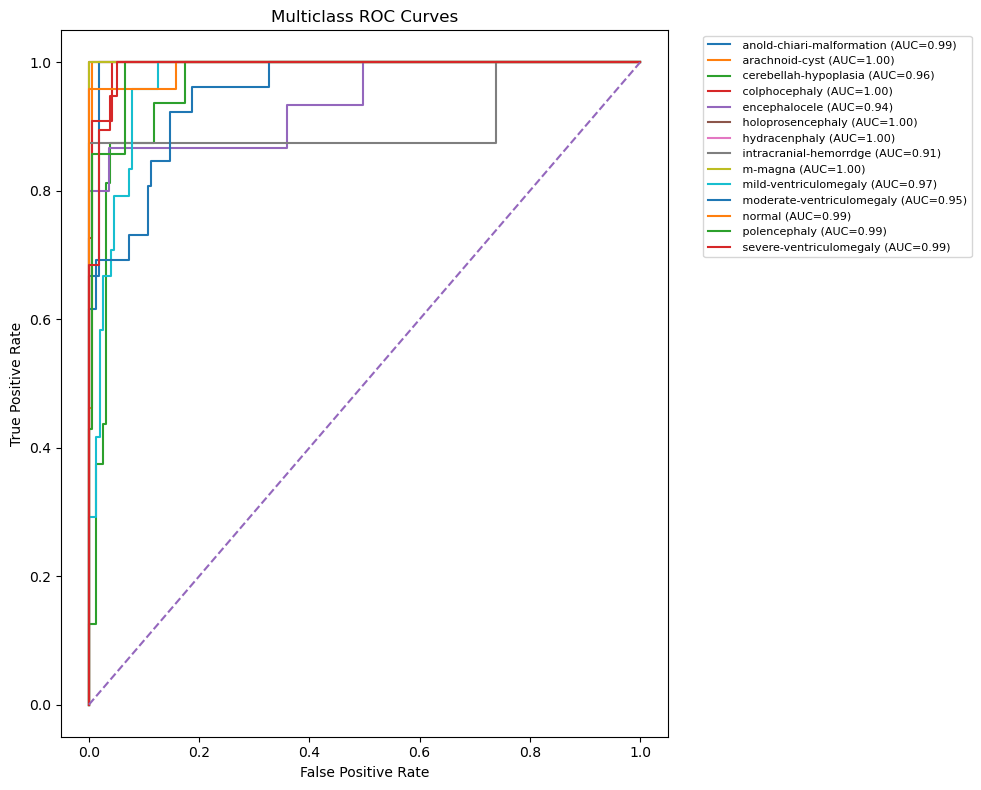

In [26]:
plt.figure(figsize=(10, 8))

for i, cls in enumerate(classes):

    if y_true_bin[:, i].sum() == 0:
        continue

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        all_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{cls} (AUC={class_auc:.2f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Multiclass ROC Curves")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    "ROC_Curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score",
        "Macro ROC-AUC",
        "Weighted ROC-AUC"
    ],

    "Value": [
        accuracy,
        precision_macro,
        recall_macro,
        f1_macro,
        precision_weighted,
        recall_weighted,
        f1_weighted,
        roc_auc_macro,
        roc_auc_weighted
    ]
})

display(final_metrics)

,Metric,Value
0,Accuracy,0.829545
1,Macro Precision,0.859044
2,Macro Recall,0.842171
3,Macro F1-Score,0.832424
4,Weighted Precision,0.842903
5,Weighted Recall,0.829545
6,Weighted F1-Score,0.827935
7,Macro ROC-AUC,NaN
8,Weighted ROC-AUC,0.973195


In [28]:
final_metrics.to_csv(
    "final_model_metrics.csv",
    index=False
)

print("Final evaluation metrics saved.")

Final evaluation metrics saved.


In [29]:
results_df = test_df.copy()

results_df["Actual"] = [
    idx_to_class[int(x)]
    for x in all_labels
]

results_df["Predicted"] = [
    idx_to_class[int(x)]
    for x in all_predictions
]

results_df["Confidence"] = np.max(
    all_probabilities,
    axis=1
)

display(
    results_df[
        [
            "filename",
            "Actual",
            "Predicted",
            "Confidence"
        ]
    ].head(20)
)

,filename,Actual,Predicted,Confidence
0,Copy-of-mild-ventriculomegaly-18c_aug_2_png_jp...,mild-ventriculomegaly,mild-ventriculomegaly,0.546881
1,Copy-of-intracranial-hemorrdge-34a_aug_4_png_j...,intracranial-hemorrdge,intracranial-hemorrdge,0.889502
2,Copy-of-moderate-ventriculomegaly-34_aug_4_png...,moderate-ventriculomegaly,moderate-ventriculomegaly,0.490967
3,Copy-of-polencephaly30k_aug_2_png_jpg.rf.05b0e...,polencephaly,polencephaly,0.633635
4,Copy-of-encephalocele-4-32c_aug_4_png_jpg.rf.0...,encephalocele,severe-ventriculomegaly,0.345845
5,Copy-of-cerebellah-hypoplasia-36o_aug_5_png_jp...,cerebellah-hypoplasia,cerebellah-hypoplasia,0.291373
6,Copy-of-mild-ventriculomegaly-20a_aug_4_png_jp...,mild-ventriculomegaly,polencephaly,0.341794
7,Copy-of-moderate-ventriculomegaly-34a_aug_3_pn...,moderate-ventriculomegaly,moderate-ventriculomegaly,0.548023
8,Copy-of-moderate-ventriculomegaly_20c_aug_3_pn...,moderate-ventriculomegaly,cerebellah-hypoplasia,0.628951
9,Patient00709_Plane3_2_of_3_aug_3_png_jpg.rf.29...,normal,normal,0.799996


In [30]:
results_df["Correct"] = (
    results_df["Actual"]
    ==
    results_df["Predicted"]
)

print(
    "Correct Predictions:",
    results_df["Correct"].sum()
)

print(
    "Incorrect Predictions:",
    (~results_df["Correct"]).sum()
)

Correct Predictions: 146
Incorrect Predictions: 30


In [31]:
print("=" * 60)
print("FINAL RESNET50 TEST EVALUATION")
print("=" * 60)

print(f"Test Images       : {len(test_dataset)}")
print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Macro Precision   : {precision_macro:.4f}")
print(f"Macro Recall      : {recall_macro:.4f}")
print(f"Macro F1-Score    : {f1_macro:.4f}")
print(f"Macro ROC-AUC     : {roc_auc_macro:.4f}")

print("=" * 60)

FINAL RESNET50 TEST EVALUATION
Test Images       : 176
Accuracy          : 82.95%
Macro Precision   : 0.8590
Macro Recall      : 0.8422
Macro F1-Score    : 0.8324
Macro ROC-AUC     : nan
